# Exploratory Data Analysis for IBM Employee Attrition 

### Problem Scope

Identify factors associated with employee attrition.

Which employee, job, compensation, and satisfaction characteristics are associated with higher attrition rates?

### Dataset Description

dataset link : https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset/data

The dataset has 1,470 employee records and 35 columns (31 after dropping constant and ID columns). The target is Attrition (Yes/No): 237 employees left (16.1%).

### Libraries & Data Loading

In [160]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [161]:
df = pd.read_csv("./data.csv")

In [162]:
df.shape

(1470, 35)

In [163]:
pd.options.display.max_columns = None
pd.options.display.max_rows = 100
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [164]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

In [165]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


checking for missing values & duplicated records

In [166]:
df.isna().sum().sum()

np.int64(0)

In [167]:
df.duplicated().sum()

np.int64(0)

our data has no missing values or duplicated rows

considering first and last 5 rows from the dataset  , we can see that EmployeeCount column and Over18 columns maybe useless

In [168]:
df.nunique().sort_values() 

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate

confirmed that columns "EmployeeCount","Over18" are unneceasssry in addition to "StandardHours", we can drop them

In [169]:
df['EmployeeNumber'].nunique()

1470

"EmployeeNumber" acts as ID , we can drop it also.

In [170]:
df = df.drop(columns=["EmployeeCount","Over18","StandardHours","EmployeeNumber"])

Lets see how is the attrition rate in the company

In [171]:
df['Attrition_numeric'] = df['Attrition'].map({"Yes":1,"No":0})
print(f"{df['Attrition_numeric'].mean():.1%}", df['Attrition_numeric'].sum() )

16.1% 237


16.1% of employees left (237 of 1,470). This is the baseline used for every comparison below.

## Categorical And Numerical Columns

considering the number of unique values, these columns could be categorical columns:
```
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
JobRole                        9
Age                           43
```

although "TrainingTimeLastYear" has low unique values , it is not categorical # Maybe removing this cell is better

In [172]:
df.dtypes

Age                         int64
Attrition                     str
BusinessTravel                str
DailyRate                   int64
Department                    str
DistanceFromHome            int64
Education                   int64
EducationField                str
EnvironmentSatisfaction     int64
Gender                        str
HourlyRate                  int64
JobInvolvement              int64
JobLevel                    int64
JobRole                       str
JobSatisfaction             int64
MaritalStatus                 str
MonthlyIncome               int64
MonthlyRate                 int64
NumCompaniesWorked          int64
OverTime                      str
PercentSalaryHike           int64
PerformanceRating           int64
RelationshipSatisfaction    int64
StockOptionLevel            int64
TotalWorkingYears           int64
TrainingTimesLastYear       int64
WorkLifeBalance             int64
YearsAtCompany              int64
YearsInCurrentRole          int64
YearsSinceLast

since we have only object and int64 datatypes , we can initially classify them: 

In [173]:
cat_cols = df.select_dtypes(include=["object", 'str']).columns.tolist()
cat_cols.remove("Attrition") 
num_cols = df.select_dtypes(include=["int64"]).columns.tolist()

In [174]:
cat_cols

['BusinessTravel',
 'Department',
 'EducationField',
 'Gender',
 'JobRole',
 'MaritalStatus',
 'OverTime']

In [175]:
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'Education',
 'EnvironmentSatisfaction',
 'HourlyRate',
 'JobInvolvement',
 'JobLevel',
 'JobSatisfaction',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'WorkLifeBalance',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager',
 'Attrition_numeric']

A lot of the categorical columns considering the data from kaggle and columns labels uses integers, we will convert them for readablity

lets explore columns that have small unique values number and convert them:

In [176]:
for col in num_cols:
  if df[col].nunique()< 10:
    print(f"{col} : {df[col].unique()}")

Education : [2 1 4 3 5]
EnvironmentSatisfaction : [2 3 4 1]
JobInvolvement : [3 2 4 1]
JobLevel : [2 1 3 4 5]
JobSatisfaction : [4 2 3 1]
PerformanceRating : [3 4]
RelationshipSatisfaction : [1 4 2 3]
StockOptionLevel : [0 1 3 2]
TrainingTimesLastYear : [0 3 2 5 1 4 6]
WorkLifeBalance : [1 3 2 4]
Attrition_numeric : [1 0]


most of the columns are mentiond in kaggle website to be categorical, except JobLevel ,StockOptionLevel and TrainingTimesLastYear (These are not mentioned)

obviously TrainingTimesLastYear is not a categorical column even if it has small number of values


In [177]:
from pandas.api.types import CategoricalDtype

# Mapping dictionaries
education = {1: "Below College", 2: "College", 3: "Bachelor", 4: "Master", 5: "Doctor"} 
environment_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
job_involvement = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
job_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
performance_rating = {1: "Low", 2: "Good", 3: "Excellent", 4: "Outstanding"} 
relationship_satisfaction = {1: "Low", 2: "Medium", 3: "High", 4: "Very High"} 
worklife_balance = {1: "Bad", 2: "Good", 3: "Better", 4: "Best"} 
job_map = {1: "Entry", 2: "Intermediate", 3: "Senior", 4: "Lead", 5: "Executive"} 
stock_map = {0: "None", 1: "Low", 2: "Medium", 3: "High"} 

# Ordered categories for each variable
ordered_mappings = {
    "Education": list(education.values()),
    "EnvironmentSatisfaction": list(environment_satisfaction.values()),
    "JobInvolvement": list(job_involvement.values()),
    "JobSatisfaction": list(job_satisfaction.values()),
    "PerformanceRating": list(performance_rating.values()),
    "RelationshipSatisfaction": list(relationship_satisfaction.values()),
    "WorkLifeBalance": list(worklife_balance.values()),
    "JobLevel": list(job_map.values()),
    "StockOptionLevel": list(stock_map.values())
}

# Mapping numeric codes to labels
df["Education"] = df["Education"].map(education)
df["EnvironmentSatisfaction"] = df["EnvironmentSatisfaction"].map(environment_satisfaction)
df["JobInvolvement"] = df["JobInvolvement"].map(job_involvement)
df["JobSatisfaction"] = df["JobSatisfaction"].map(job_satisfaction)
df["PerformanceRating"] = df["PerformanceRating"].map(performance_rating)
df["RelationshipSatisfaction"] = df["RelationshipSatisfaction"].map(relationship_satisfaction)
df["WorkLifeBalance"] = df["WorkLifeBalance"].map(worklife_balance)
df["JobLevel"] = df["JobLevel"].map(job_map)
df["StockOptionLevel"] = df["StockOptionLevel"].map(stock_map)

# Convert all to ordered categorical
for col, order in ordered_mappings.items():
    dtype = CategoricalDtype(categories=order, ordered=True)
    df[col] = df[col].astype(dtype)

now we can check our datatypes to make sure everything is right 

In [128]:
df.dtypes

Age                            int64
Attrition                        str
BusinessTravel                   str
DailyRate                      int64
Department                       str
DistanceFromHome               int64
Education                   category
EducationField                   str
EnvironmentSatisfaction     category
Gender                           str
HourlyRate                     int64
JobInvolvement              category
JobLevel                    category
JobRole                          str
JobSatisfaction             category
MaritalStatus                    str
MonthlyIncome                  int64
MonthlyRate                    int64
NumCompaniesWorked             int64
OverTime                         str
PercentSalaryHike              int64
PerformanceRating           category
RelationshipSatisfaction    category
StockOptionLevel            category
TotalWorkingYears              int64
TrainingTimesLastYear          int64
WorkLifeBalance             category
Y

In [129]:
cat_cols = df.select_dtypes(include=["object",'category']).columns.tolist()
cat_cols.remove("Attrition") 
num_cols = df.select_dtypes(include=["int64"]).columns.tolist()

C:\Users\abd alrahman\AppData\Local\Temp\ipykernel_19492\2808311317.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=["object",'category']).columns.tolist()


In [130]:
for col in cat_cols:
  print(f"{col}: {df[col].unique()}")

BusinessTravel: <StringArray>
['Travel_Rarely', 'Travel_Frequently', 'Non-Travel']
Length: 3, dtype: str
Department: <StringArray>
['Sales', 'Research & Development', 'Human Resources']
Length: 3, dtype: str
Education: ['College', 'Below College', 'Master', 'Bachelor', 'Doctor']
Categories (5, str): ['Below College' < 'College' < 'Bachelor' < 'Master' < 'Doctor']
EducationField: <StringArray>
[   'Life Sciences',            'Other',          'Medical',
        'Marketing', 'Technical Degree',  'Human Resources']
Length: 6, dtype: str
EnvironmentSatisfaction: ['Medium', 'High', 'Very High', 'Low']
Categories (4, str): ['Low' < 'Medium' < 'High' < 'Very High']
Gender: <StringArray>
['Female', 'Male']
Length: 2, dtype: str
JobInvolvement: ['High', 'Medium', 'Very High', 'Low']
Categories (4, str): ['Low' < 'Medium' < 'High' < 'Very High']
JobLevel: ['Intermediate', 'Entry', 'Senior', 'Lead', 'Executive']
Categories (5, str): ['Entry' < 'Intermediate' < 'Senior' < 'Lead' < 'Executive']
Job

In [131]:
num_cols

['Age',
 'DailyRate',
 'DistanceFromHome',
 'HourlyRate',
 'MonthlyIncome',
 'MonthlyRate',
 'NumCompaniesWorked',
 'PercentSalaryHike',
 'TotalWorkingYears',
 'TrainingTimesLastYear',
 'YearsAtCompany',
 'YearsInCurrentRole',
 'YearsSinceLastPromotion',
 'YearsWithCurrManager',
 'Attrition_numeric']

In [132]:
cat_cols

['BusinessTravel',
 'Department',
 'Education',
 'EducationField',
 'EnvironmentSatisfaction',
 'Gender',
 'JobInvolvement',
 'JobLevel',
 'JobRole',
 'JobSatisfaction',
 'MaritalStatus',
 'OverTime',
 'PerformanceRating',
 'RelationshipSatisfaction',
 'StockOptionLevel',
 'WorkLifeBalance']

# Numerical Columns

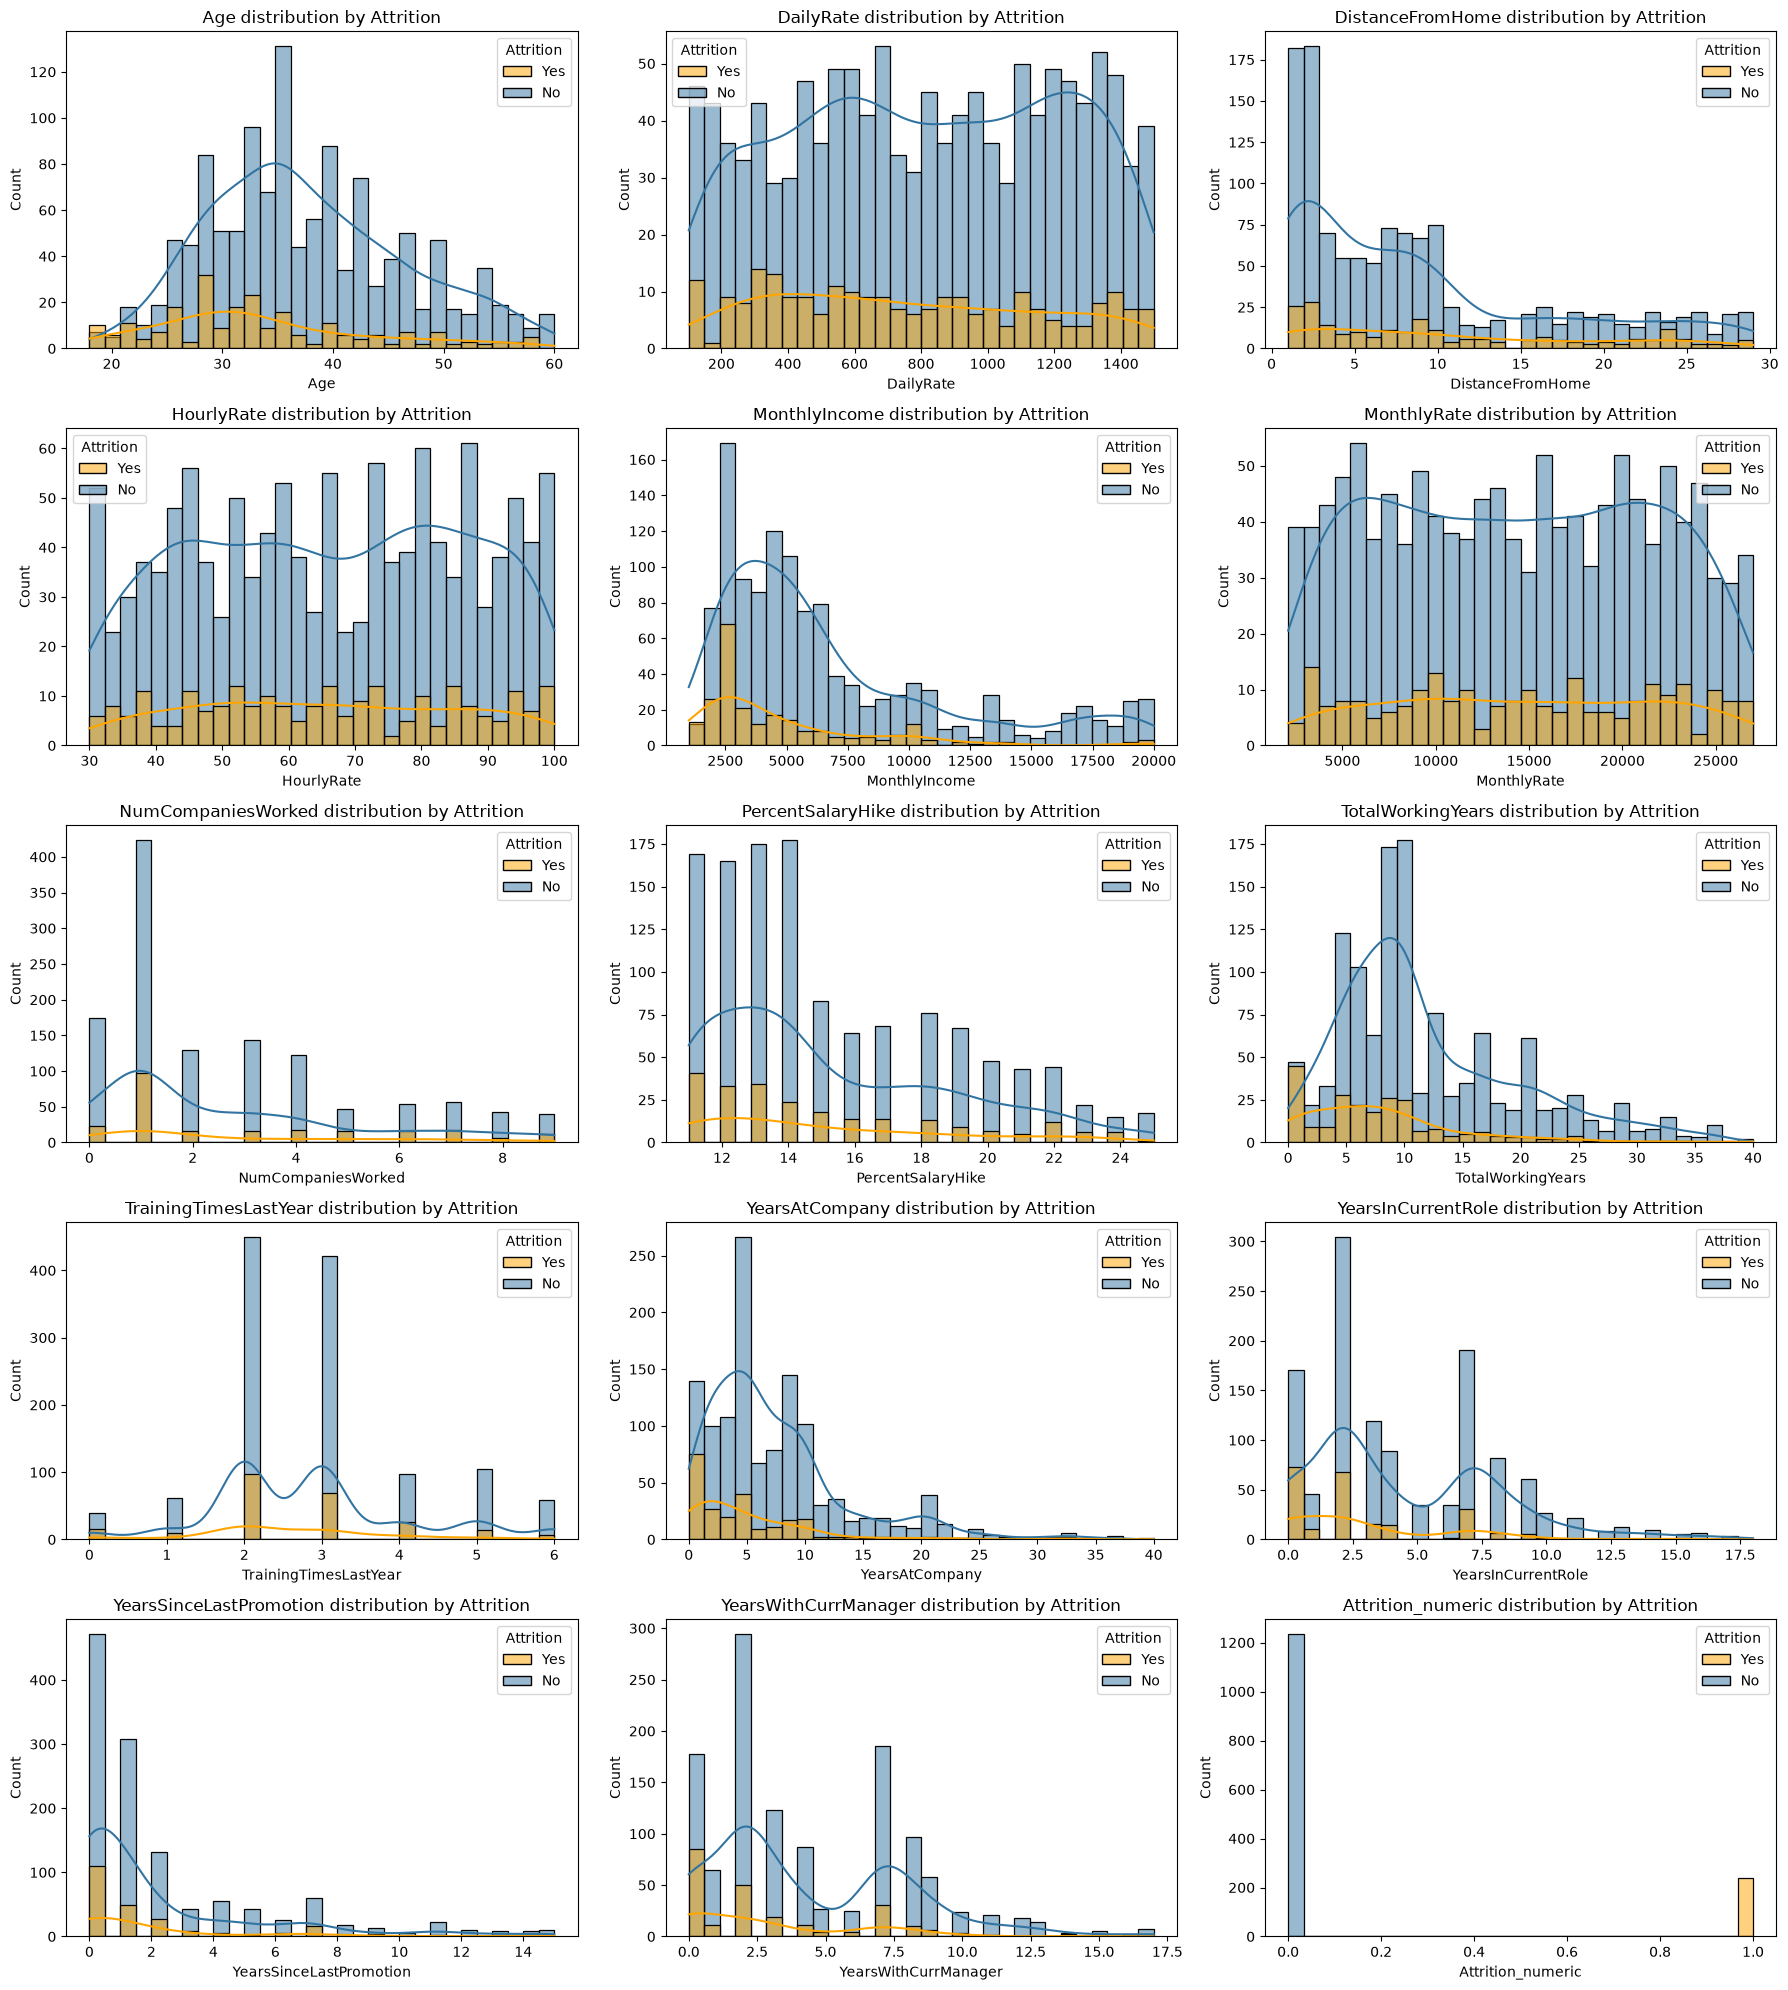

In [133]:
color_map = {"Yes": "orange", "No": "#3274A1"}

n_cols = 3
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axes = axes.flatten()

for idx, col in enumerate(num_cols):
    sns.histplot(
        data=df,
        x=col,
        hue="Attrition",
        multiple="layer",
        bins=30,
        
        ax=axes[idx],
        kde=True,
        palette=color_map
    )
    axes[idx].set_title(f"{col} distribution by Attrition")

# Remove empty plots
for i in range(len(num_cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

the useful info that i found from the distributions that monthly income is right skewd 

lets see the correlation between numerical features

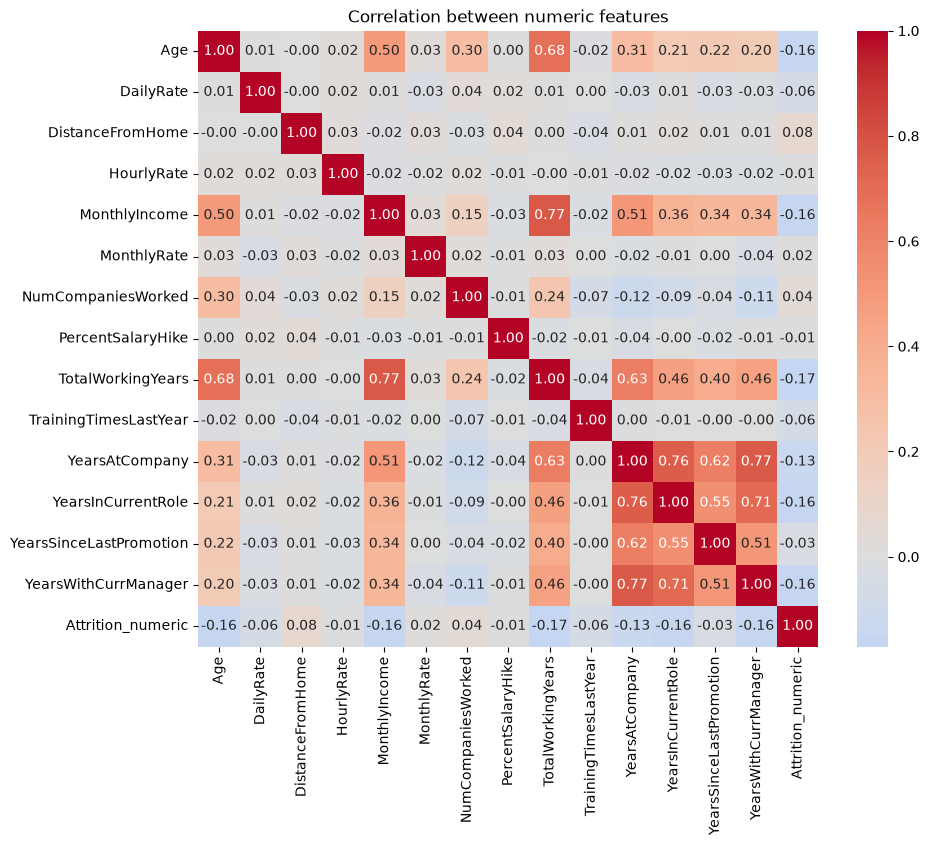

In [134]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

we can see that :
- Monthly income has high correlation (0.77) with Total working years, 0.51 with YearsAtCompany and (0.5) with Age, which makes sense since salary goes up as careers advance 
- total working years, years at company, ... that red block in the right corner have high correlation which is also logical
- we notice that Age, Monthly income, total working years have negative correlation with attrition (-0.17), which is not high negative but can be considered 
- Distance from home have positive correlation (0.08) with attrition, can be studied

## Investegation by groups

we can split columns into categories, and make an analysis for each category alone

In [135]:
column_groups = {
    "Compensation": [
        "HourlyRate", "DailyRate", "MonthlyRate",
        "MonthlyIncome", "PercentSalaryHike", "StockOptionLevel"
    ],

    "Career History": [
        "TotalWorkingYears", "YearsAtCompany",
        "YearsInCurrentRole", "YearsSinceLastPromotion",
        "YearsWithCurrManager", "NumCompaniesWorked"
    ],

    "Education and Development": [
        "Education", "EducationField", # "TrainingTimesLastYear" we will handle this column in a seperate way.
    ],

    "Demographics and Personal Life": [
        "Age", "Gender", "MaritalStatus"
    ],

    "Job and Satisfaction": [
        "EnvironmentSatisfaction", "JobInvolvement",
        "JobLevel", "JobRole", "JobSatisfaction",
        "PerformanceRating", "WorkLifeBalance"
    ],

    "Work Conditions": [
        "OverTime", "BusinessTravel", "DistanceFromHome"
    ],

    "Organization": [
        "Department"
    ],
}

lets plot the data considering Attrition to get better understanding of it

In [178]:
from pandas.api.types import is_numeric_dtype

def plot_category(
    df,
    column_groups,
    category,
    target="Attrition",
    n_cols=3
):
    if category not in column_groups:
        available = ", ".join(column_groups.keys())
        raise ValueError(
            f"Unknown category '{category}'. Available categories: {available}"
        )

    columns = [
        column for column in column_groups[category]
        if column in df.columns and column != target
    ]

    if not columns:
        raise ValueError(f"No valid columns found for '{category}'.")

    n_rows = math.ceil(len(columns) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 4.5 * n_rows)
    )

    axes = np.atleast_1d(axes).flatten()

    for index, column in enumerate(columns):
        ax = axes[index]

        if is_numeric_dtype(df[column]):
            # Numerical columns: compare distributions by attrition
            sns.boxplot(
                data=df,
                x=target,
                y=column,
                hue=target,
                palette=color_map,
                legend=False,
                ax=ax
            )
            ax.set_xlabel("Attrition")
            ax.set_ylabel(column)

        else:
            # Categorical columns: compare attrition counts
            sns.countplot(
                data=df,
                x=column,
                hue=target,
                palette=color_map,
                ax=ax
            )
            ax.set_xlabel(column)
            ax.set_ylabel("Employee Count")
            ax.tick_params(axis="x", rotation=45)

        ax.set_title(f"{column} vs {target}")

    # Remove unused subplot axes
    for ax in axes[len(columns):]:
        fig.delaxes(ax)

    fig.suptitle(f"{category} Analysis", fontsize=16)
    plt.tight_layout()
    plt.show()

    # return fig, axes


from IPython.display import display


def display_category_tables(
    df,
    column_groups,
    category,
    target="Attrition"
):
    columns = [
        column for column in column_groups[category]
        if column in df.columns and column != target
    ]

    for column in columns:
        table = pd.crosstab(df[column], df[target])
        table = table.reindex(columns=["No", "Yes"], fill_value=0)

        table["Total"] = table["No"] + table["Yes"]
        table["AttritionRate"] = (
            table["Yes"] / table["Total"] * 100
        ).round(2)

        table = table.reset_index()
        table.columns.name = None
        table = table.rename(columns={column: column})
        table = table.sort_values('AttritionRate')
        print(f"\n{column}")
        display(table)

### Compensation

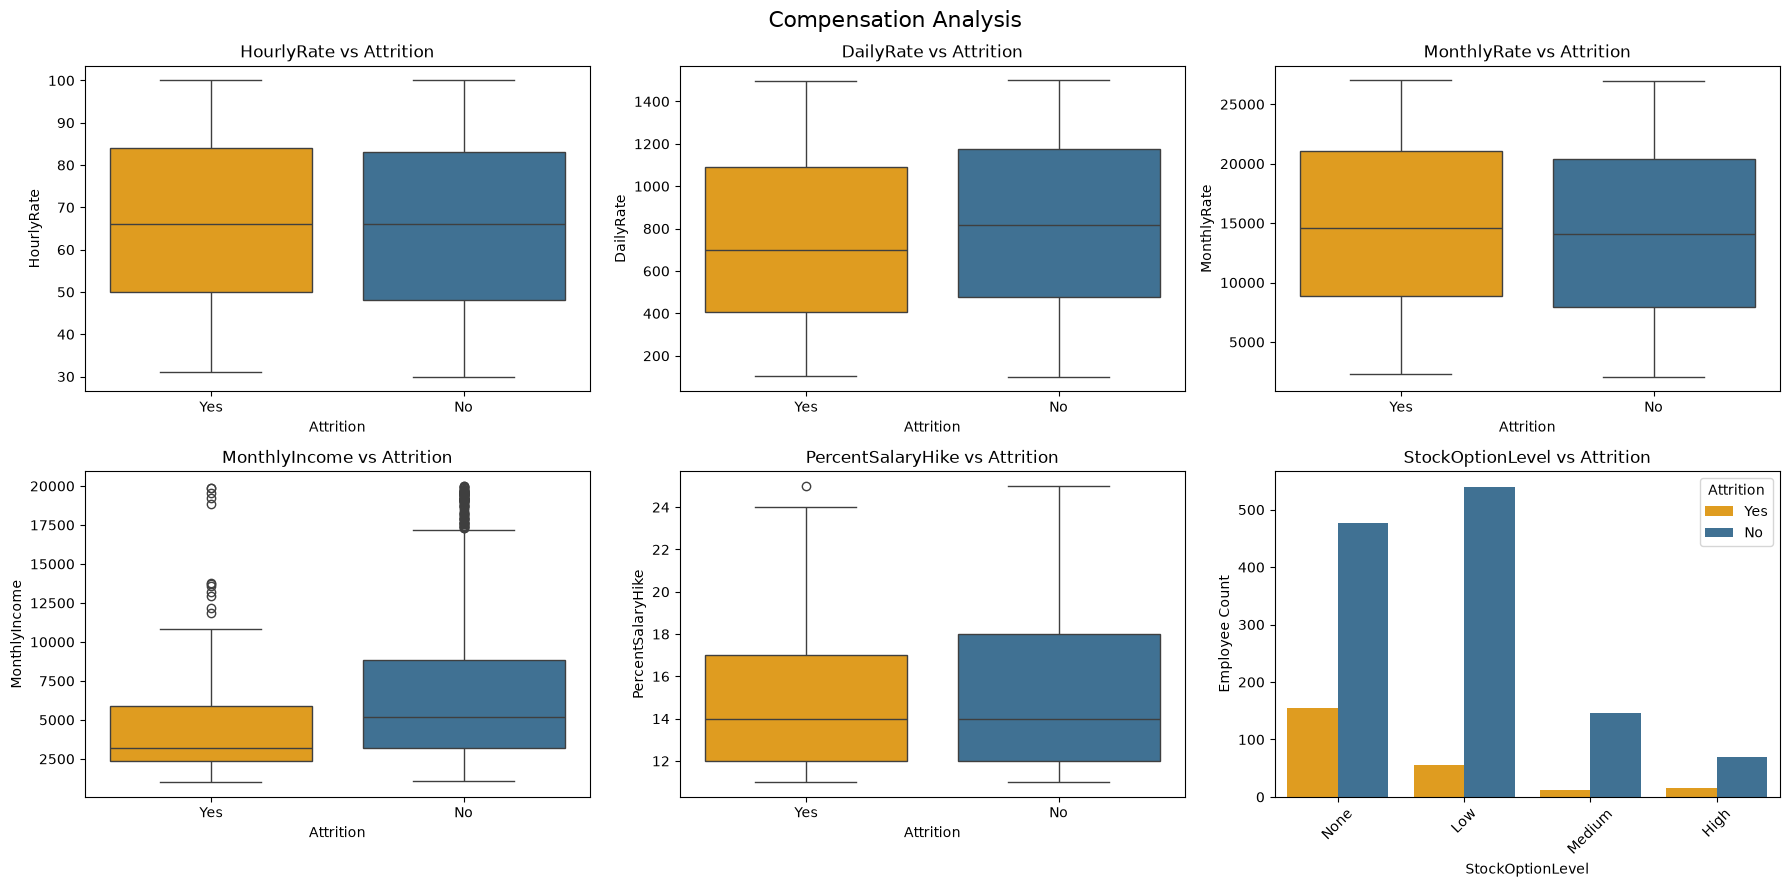

In [137]:
plot_category(df,column_groups,"Compensation")

In [180]:
stock_summary = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("StockOptionLevel", observed=True)
      .agg(
          Employees=("Left", "size"),
          EmployeesLeft=("Left", "sum"),
          AttritionRate=("Left", "mean")
      )
      .assign(AttritionRate=lambda x: x["AttritionRate"].mul(100))
      .reset_index()
)

stock_summary.sort_values('AttritionRate')

,StockOptionLevel,Employees,EmployeesLeft,AttritionRate
2,Medium,158,12,7.594937
1,Low,596,56,9.395973
3,High,85,15,17.647059
0,None,631,154,24.405705


- The distributions of HourlyRate, DailyRate, MonthlyRate, and PercentSalaryHike appear similar for employees who stayed and those who left. Therefore, no strong association with attrition is apparent from these plots.

- Employees who left have a lower MonthlyIncome than employees who stayed. This suggests that lower income may be associated with higher attrition

- Employees with no stock options had a 24.4% attrition rate, compared with 16.1% overall. Employees with low or medium stock options had lower attrition rates. The high-stock-option group had a smaller sample and its attrition rate was closer to the overall rate, so the relationship is not strictly linear.

### Career History

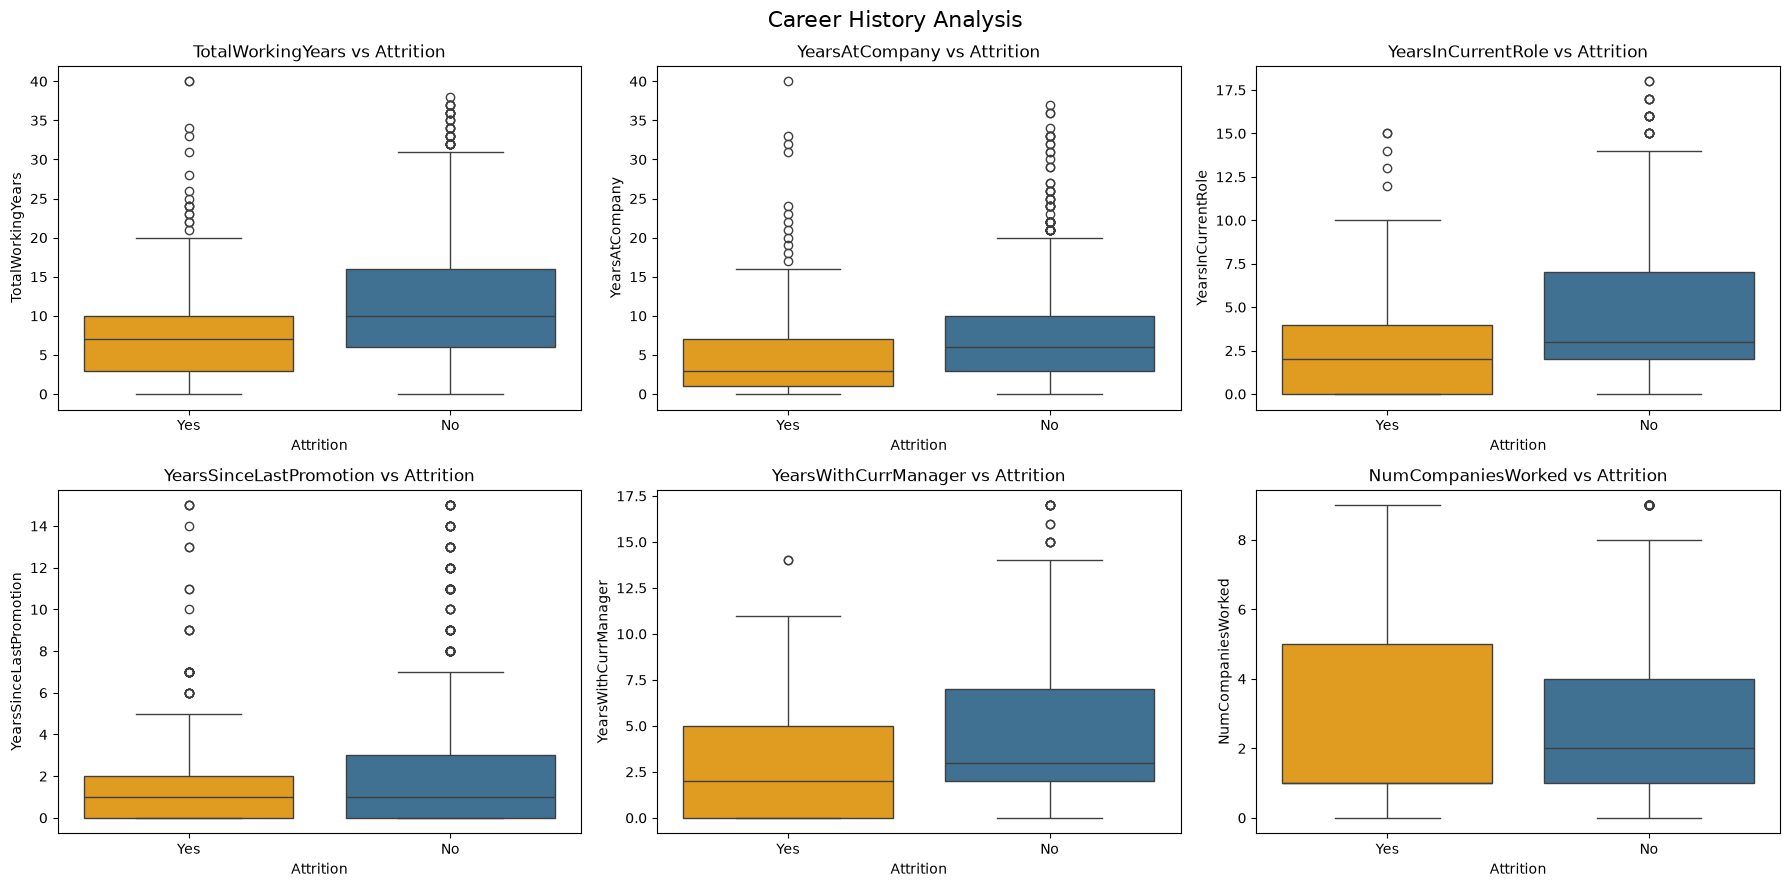

In [139]:
plot_category(df,column_groups,"Career History")

Employees with fewer years at the company generally show higher attrition rates. However, this is an observed association, not proof that shorter tenure causes employees to leave.

### Education and Development

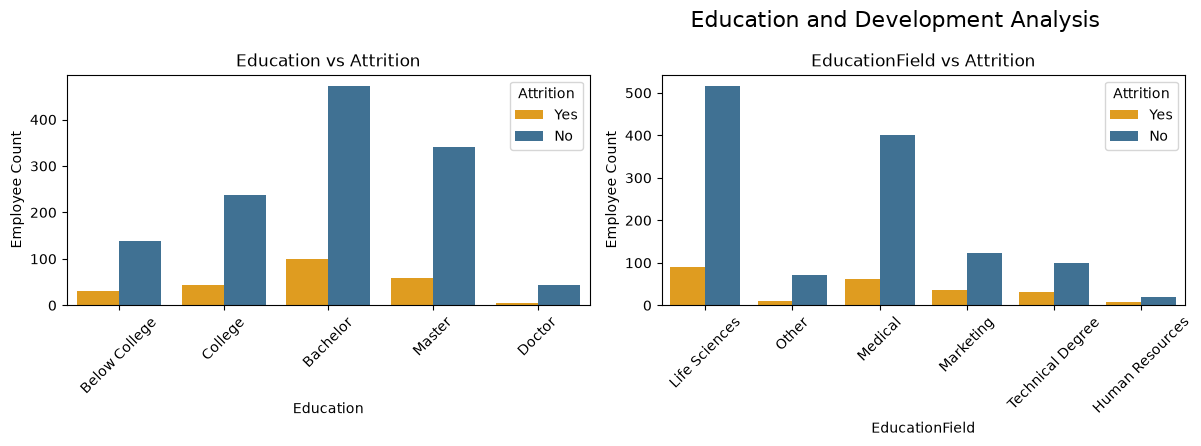

In [140]:
plot_category(df,column_groups,"Education and Development")

In [181]:
display_category_tables(df,column_groups,"Education and Development")


Education


,Education,No,Yes,Total,AttritionRate
4,Doctor,43,5,48,10.42
3,Master,340,58,398,14.57
1,College,238,44,282,15.60
2,Bachelor,473,99,572,17.31
0,Below College,139,31,170,18.24



EducationField


,EducationField,No,Yes,Total,AttritionRate
4,Other,71,11,82,13.41
3,Medical,401,63,464,13.58
1,Life Sciences,517,89,606,14.69
2,Marketing,124,35,159,22.01
5,Technical Degree,100,32,132,24.24
0,Human Resources,20,7,27,25.93


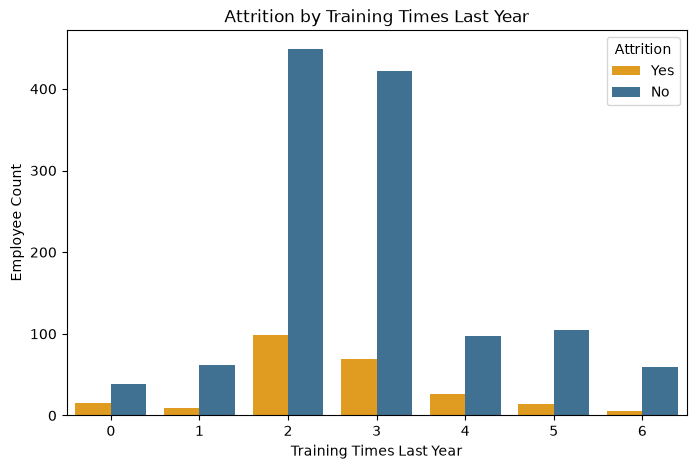

In [142]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="TrainingTimesLastYear",
    hue="Attrition",
    palette=color_map
)

plt.xlabel("Training Times Last Year")
plt.ylabel("Employee Count")
plt.title("Attrition by Training Times Last Year")
plt.show()

In [182]:
training_summary = (
    df.assign(Left=df["Attrition"].eq("Yes"))
      .groupby("TrainingTimesLastYear")["Left"]
      .agg(
          Employees="size",
          EmployeesLeft="sum",
          AttritionRate="mean"
      )
      .assign(
          AttritionRate=lambda table: table["AttritionRate"].mul(100)
      )
      .reset_index()
)

training_summary.sort_values("AttritionRate")

,TrainingTimesLastYear,Employees,EmployeesLeft,AttritionRate
6,6,65,6,9.230769
5,5,119,14,11.764706
1,1,71,9,12.676056
3,3,491,69,14.052953
2,2,547,98,17.915905
4,4,123,26,21.138211
0,0,54,15,27.777778


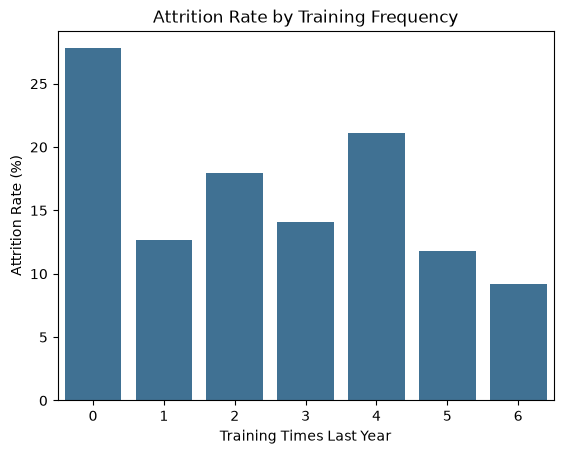

In [144]:
sns.barplot(
    data=training_summary,
    x="TrainingTimesLastYear",
    y="AttritionRate",
    color="#3274A1"
)

plt.ylabel("Attrition Rate (%)")
plt.xlabel("Training Times Last Year")
plt.title("Attrition Rate by Training Frequency")
plt.show()

Attrition rates are relatively similar across education levels, Education Fields and Training times last year, so this dataset does not show a strong association between an employee’s education and attrition.

- Attrition is fairly close to our baseline across education levels (10.4%–18.2%).
-Education field varies more than Education Level: Technical Degree 24.2% , Marketing 22.0% and HR 25.9% (only 7 left out of 27..) vs about 13.4%–14.7% for Life Sciences, Medical and Other. 
- Training frequency shows no steady pattern

### Demographics and Personal Life

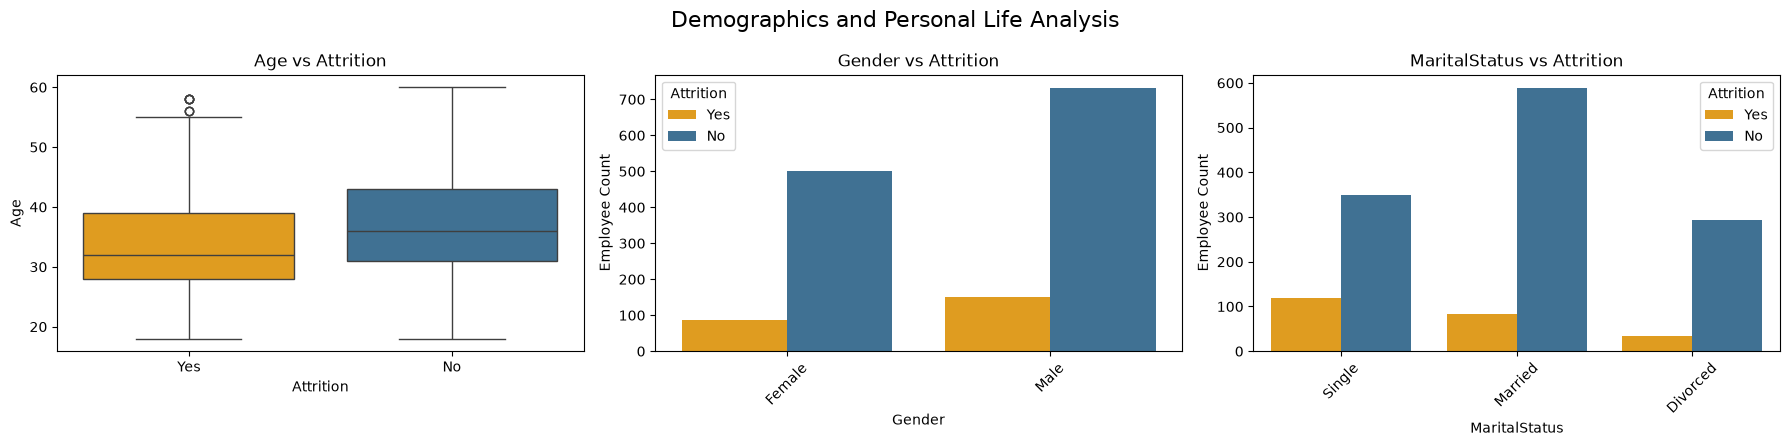

In [146]:
plot_category(df,column_groups,"Demographics and Personal Life")


In [147]:
display_category_tables(df,column_groups,"Demographics and Personal Life")



Age


,Age,No,Yes,Total,AttritionRate
0,18,4,4,8,50.00
1,19,3,6,9,66.67
2,20,5,6,11,54.55
3,21,7,6,13,46.15
4,22,11,5,16,31.25
5,23,10,4,14,28.57
6,24,19,7,26,26.92
7,25,20,6,26,23.08
8,26,27,12,39,30.77
9,27,45,3,48,6.25



Gender


,Gender,No,Yes,Total,AttritionRate
0,Female,501,87,588,14.80
1,Male,732,150,882,17.01



MaritalStatus


,MaritalStatus,No,Yes,Total,AttritionRate
0,Divorced,294,33,327,10.09
1,Married,589,84,673,12.48
2,Single,350,120,470,25.53


- Marital status: 25.5% of Single employees left (120 of 470), vs 12.5% of Married and 10.1% of Divorced, compared with 16.1% overall. Singles are 32% of employees but 51% of leavers (120 of 237).
- Gender: 17.0% of men vs 14.8% of women left, a small difference.

### Job and Satisfaction

- Sales Representatives have high attrition rate than all other Roles - (39.8%)  vs 16.1% overall- HR and Laboratory Tech have around 23% attrition rate which is high, others are normal in our comparasion.
- Entry level left at 26.3% vs 4.7%–14.7% for the other levels.
- Performance rating has only two values (3 and 4), with 16.1% vs 16.4%, so it has almost no variation to learn from.
- Work-life balance: "Bad" working condition have high attrition rate (31.2%). The other three are 14.2%–17.6% with no steady trend.
- Low Job Satsfaction have 22.84% attrition rate
- Low Job Involvement have 33.73% attrition rate


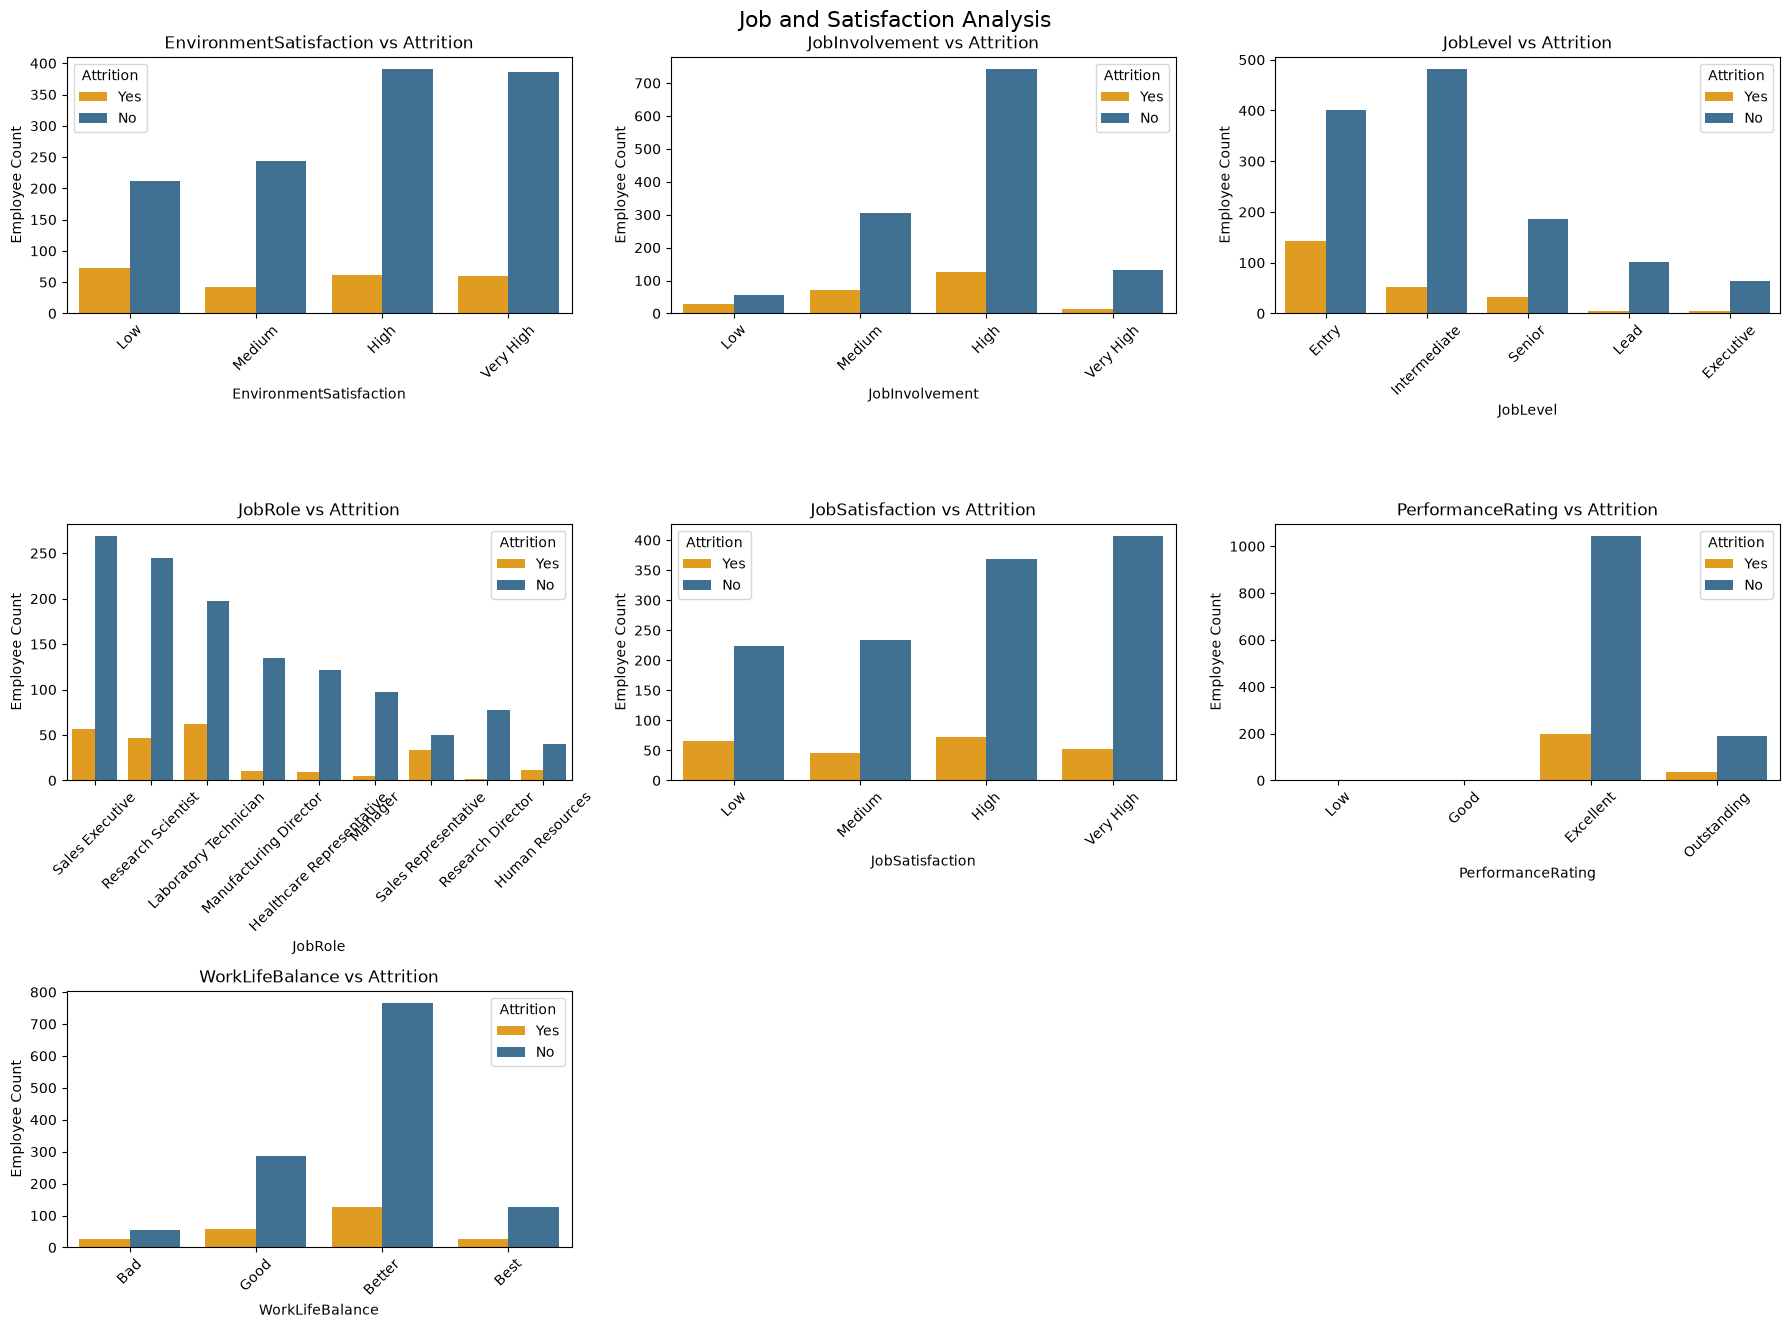

In [148]:
plot_category(df,column_groups,"Job and Satisfaction")


In [149]:
display_category_tables(df,column_groups,"Job and Satisfaction")



EnvironmentSatisfaction


,EnvironmentSatisfaction,No,Yes,Total,AttritionRate
0,Low,212,72,284,25.35
1,Medium,244,43,287,14.98
2,High,391,62,453,13.69
3,Very High,386,60,446,13.45



JobInvolvement


,JobInvolvement,No,Yes,Total,AttritionRate
0,Low,55,28,83,33.73
1,Medium,304,71,375,18.93
2,High,743,125,868,14.40
3,Very High,131,13,144,9.03



JobLevel


,JobLevel,No,Yes,Total,AttritionRate
0,Entry,400,143,543,26.34
1,Intermediate,482,52,534,9.74
2,Senior,186,32,218,14.68
3,Lead,101,5,106,4.72
4,Executive,64,5,69,7.25


... (4 outputs left out)


PerformanceRating


,PerformanceRating,No,Yes,Total,AttritionRate
0,Excellent,1044,200,1244,16.08
1,Outstanding,189,37,226,16.37



WorkLifeBalance


,WorkLifeBalance,No,Yes,Total,AttritionRate
0,Bad,55,25,80,31.25
1,Good,286,58,344,16.86
2,Better,766,127,893,14.22
3,Best,126,27,153,17.65


### Work Conditions

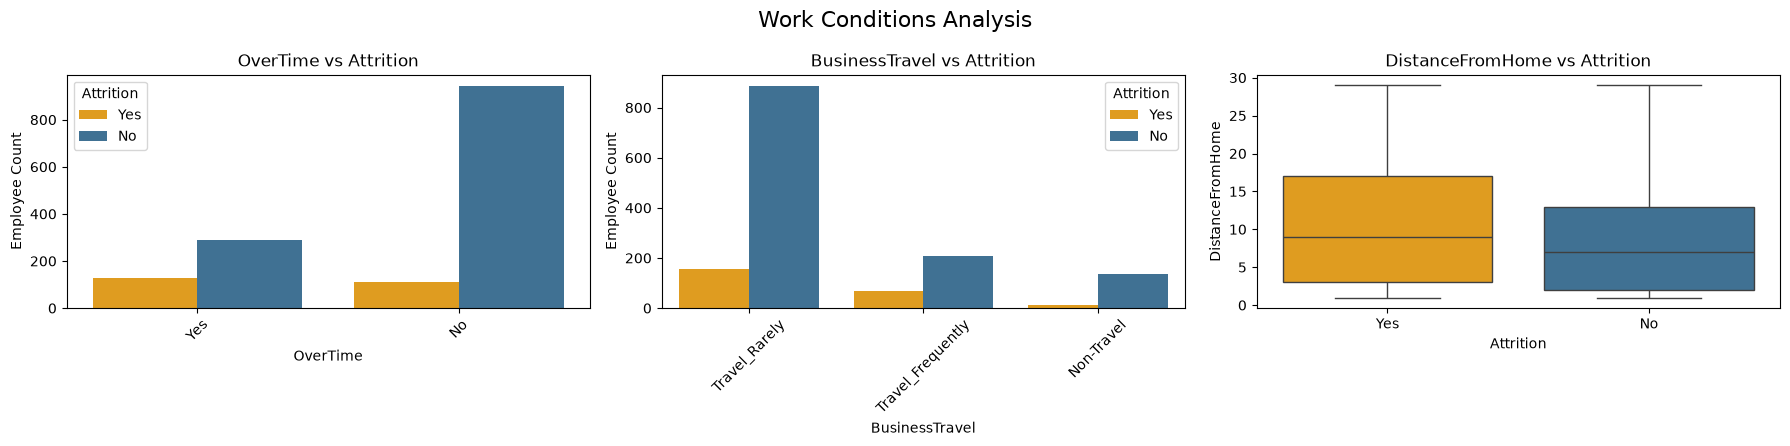

In [150]:
plot_category(df,column_groups,"Work Conditions")


In [157]:
display_category_tables(df,column_groups,"Work Conditions")


OverTime


,OverTime,No,Yes,Total,AttritionRate
0,No,944,110,1054,10.44
1,Yes,289,127,416,30.53



BusinessTravel


,BusinessTravel,No,Yes,Total,AttritionRate
0,Non-Travel,138,12,150,8.00
1,Travel_Frequently,208,69,277,24.91
2,Travel_Rarely,887,156,1043,14.96



DistanceFromHome


,DistanceFromHome,No,Yes,Total,AttritionRate
0,1,182,26,208,12.50
1,2,183,28,211,13.27
2,3,70,14,84,16.67
3,4,55,9,64,14.06
4,5,55,10,65,15.38
5,6,52,7,59,11.86
6,7,73,11,84,13.10
7,8,70,10,80,12.50
8,9,67,18,85,21.18
9,10,75,11,86,12.79


- Overtime: 30.5% of employees working overtime left (416) vs 10.4% without (1054), against a 16.1% baseline.
- Business travel: Travel_Frequently 24.9% (277), Travel_Rarely 15.0% (1043), Non-Travel 8.0% (150).

### Organization

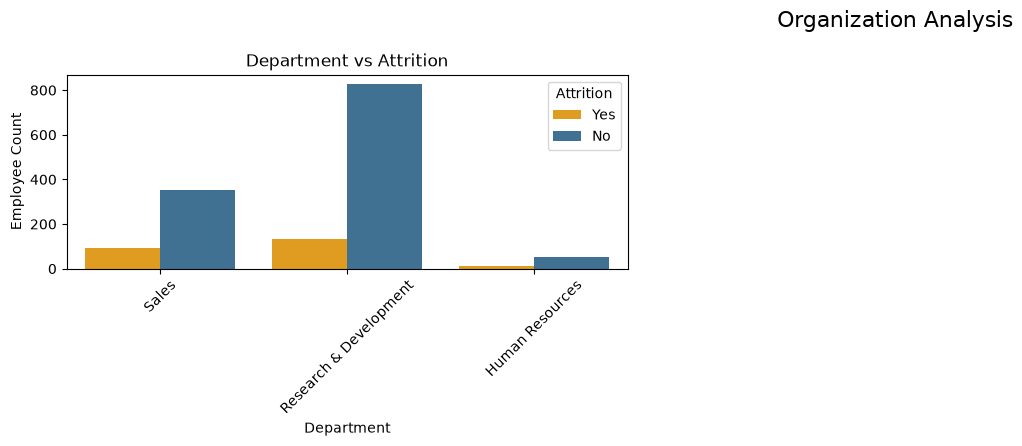

In [151]:
plot_category(df,column_groups,"Organization")


In [152]:
display_category_tables(df,column_groups, "Organization")


Department


,Department,No,Yes,Total,AttritionRate
0,Human Resources,51,12,63,19.05
1,Research & Development,828,133,961,13.84
2,Sales,354,92,446,20.63


Sales attrition rate is 20.6% (446 total, 92 left), HR is 19.0% (63 total, 12 left) and R&D at 13.8% (961 total, 133 left), against 16.1% overall. Sales and HR are above the baseline and R&D is below it.

In [185]:
income_by_level = (df.groupby(["JobLevel", "Attrition"], observed=True)["MonthlyIncome"]
                     .agg(["count", "median","mean"]).unstack())
income_by_level

count        median                   mean              
Attrition       No  Yes       No      Yes            No           Yes
JobLevel                                                             
Entry          400  143   2719.0   2437.0   2854.407500   2598.125874
Intermediate   482   52   5334.5   5346.0   5474.495851   5759.788462
Senior         186   32   9982.5   9887.0   9891.032258   9388.406250
Lead           101    5  16307.0  13194.0  15620.287129  13150.400000
Executive       64    5  19199.5  19545.0  19170.578125  19463.800000

Leavers earn less overall, but they are concentrated in Entry level, where pay is low for everyone (143 of 237 leavers). Within Intermediate, Senior and Executive levels the median incomes of leavers and stayers are almost identical. Only Entry level shows a gap (2,437 vs 2,719). So the pay–attrition link is mostly a job-level effect. (Lead shows a bigger gap, but only 5 employees left there, so it isn't reliable.)

In [186]:
df["TenureBucket"] = pd.cut(df["YearsAtCompany"], bins=[-1, 1, 3, 5, 10, 40],
                            labels=["0-1", "2-3", "4-5", "6-10", "10+"])
tenure = df.groupby("TenureBucket", observed=True)["Attrition_numeric"].agg(
    Employees="size", AttritionRate="mean")
tenure["AttritionRate"] *= 100
tenure.round(1)

,Employees,AttritionRate
TenureBucket,,
0-1,215,34.9
2-3,255,18.4
4-5,306,13.1
6-10,448,12.3
10+,246,8.1


## Key Findings
Baseline: 16.1% of employees left (237 of 1,470).
1. Overtime is the strongest single signal: 30.5% of employees working overtime left (n = 416) vs 10.4% without (n = 1,054).
2. Early tenure is high risk: 34.9% of employees with 0–1 years at the company left (n = 215), falling to 8.1% after 10+ years (n = 246).
3. Entry-level jobs carry most of the attrition: 26.3% (n = 543), and 143 of the 237 leavers. By role, Sales Representatives left at 39.8% (n = 83) and Laboratory Technicians at 23.9% (n = 259), vs 2.5% for Research Directors (n = 80).
4. The pay–attrition link is mostly a job-level effect: leavers earn less overall, but within Intermediate, Senior and Executive levels incomes are almost identical.
5. Other groups with higher attrition: Single employees (25.5%, n = 470), frequent business travelers (24.9%, n = 277) and employees with no stock options (24.4%, n = 631). These overlap with early-career employees.
6. Little signal: HourlyRate, DailyRate, MonthlyRate, PercentSalaryHike, PerformanceRating and Gender.